In [9]:
import time

# ============================================================
# Пример 1: Ручной замер с perf_counter
# ============================================================

def sum_with_loop(n):
    """Суммирование через цикл"""
    total = 0
    for i in range(n):
        total += i
    return total

def sum_with_builtin(n):
    """Суммирование через встроенную функцию"""
    return sum(range(n))

# --- Замер первого варианта ---
start = time.perf_counter()
result1 = sum_with_loop(1_000_000)
end = time.perf_counter()
time_loop = end - start
print(f"Цикл:       {time_loop:.6f} сек, результат={result1}")

# --- Замер второго варианта ---
start = time.perf_counter()
result2 = sum_with_builtin(1_000_000)
end = time.perf_counter()
time_builtin = end - start
print(f"Встроенная: {time_builtin:.6f} сек, результат={result2}")

print(f"\nВстроенная функция быстрее в {time_loop / time_builtin:.1f} раз")

Цикл:       0.145142 сек, результат=499999500000
Встроенная: 0.086711 сек, результат=499999500000

Встроенная функция быстрее в 1.7 раз


timeit

In [11]:
import timeit

# ============================================================
# Пример 2: Сравнение двух способов конкатенации строк
# ============================================================

# Вариант 1: конкатенация через +=
stmt1 = """
s = ""
for i in range(100):
    s += str(i)
"""

# Вариант 2: join
stmt2 = """
s = "".join(str(i) for i in range(100))
"""

# number=10000 — выполнить каждый фрагмент 10000 раз
# repeat=5 — провести 5 серий и взять лучшую
times1 = timeit.repeat(stmt1, number=10000, repeat=5)
times2 = timeit.repeat(stmt2, number=10000, repeat=5)

best1 = min(times1) / 10000 * 1_000_000  # микросекунды
best2 = min(times2) / 10000 * 1_000_000

print(f"+= конкатенация: {best1:.2f} мкс на операцию")
print(f"join:            {best2:.2f} мкс на операцию")
print(f"join быстрее в {best1 / best2:.1f} раз")

print(f"\nВсе замеры для +=:   {[f'{t/10000*1e6:.2f}' for t in times1]} мкс")
print(f"Все замеры для join: {[f'{t/10000*1e6:.2f}' for t in times2]} мкс")

+= конкатенация: 23.33 мкс на операцию
join:            26.79 мкс на операцию
join быстрее в 0.9 раз

Все замеры для +=:   ['50.77', '23.33', '28.52', '29.44', '23.90'] мкс
Все замеры для join: ['30.20', '32.95', '26.79', '29.92', '32.10'] мкс


Часть 2: Измерение памяти с tracemalloc
Стандартный модуль для отслеживания памяти в Python.


In [12]:
import tracemalloc

# ============================================================
# Пример 3: Память для list vs generator
# ============================================================

N = 1_000_000

# --- Вариант 1: список (хранит все элементы) ---
tracemalloc.start()
list_data = [i for i in range(N)]
current, peak = tracemalloc.get_traced_memory()
tracemalloc.stop()

print("=== Список ===")
print(f"Текущая память: {current / 1024:.1f} КБ")
print(f"Пиковая память: {peak / 1024:.1f} КБ")

# --- Вариант 2: генератор (вычисляет по одному) ---
tracemalloc.start()
gen_data = (i for i in range(N))
current_gen, peak_gen = tracemalloc.get_traced_memory()
tracemalloc.stop()

print("\n=== Генератор (до вычислений) ===")
print(f"Текущая память: {current_gen / 1024:.1f} КБ")
print(f"Пиковая память: {peak_gen / 1024:.1f} КБ")

# --- Потребление при фактической обработке ---
tracemalloc.start()
total = sum(gen_data)
current_gen2, peak_gen2 = tracemalloc.get_traced_memory()
tracemalloc.stop()

print("\n=== Генератор (во время sum) ===")
print(f"Пиковая память: {peak_gen2 / 1024:.1f} КБ")
print(f"Результат суммы: {total}")

=== Список ===
Текущая память: 39494.1 КБ
Пиковая память: 39512.3 КБ

=== Генератор (до вычислений) ===
Текущая память: 1.6 КБ
Пиковая память: 27.9 КБ

=== Генератор (во время sum) ===
Пиковая память: 19.7 КБ
Результат суммы: 499999500000


Память для list vs set vs dict

In [13]:
import tracemalloc

# ============================================================
# Пример 4: Память для разных структур данных
# ============================================================

N = 500_000

def measure_memory(data_type):
    """Измеряет пиковую память при создании структуры."""
    tracemalloc.start()
    if data_type == "list":
        data = list(range(N))
    elif data_type == "set":
        data = set(range(N))
    elif data_type == "dict":
        data = {i: i for i in range(N)}
    current, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return peak / 1024 / 1024  # МБ

print("=== Пиковая память для 500,000 элементов ===")
print(f"list: {measure_memory('list'):.1f} МБ")
print(f"set:  {measure_memory('set'):.1f} МБ")
print(f"dict: {measure_memory('dict'):.1f} МБ")

=== Пиковая память для 500,000 элементов ===
list: 19.1 МБ
set:  33.6 МБ
dict: 40.7 МБ


Часть 3: Полный пример — сравнение алгоритмов с визуализацией
Объединяем всё: замеряем время и память, строим графики.

Запуск бенчмарков...

Размер n=100:
  Вложенные циклы       время=   0.413 мс  память=  0.00 МБ
  Сортировка            время=   0.012 мс  память=  0.00 МБ
  Множество (set)       время=   0.013 мс  память=  0.01 МБ

Размер n=200:
  Вложенные циклы       время=   1.510 мс  память=  0.00 МБ
  Сортировка            время=   0.020 мс  память=  0.00 МБ
  Множество (set)       время=   0.023 мс  память=  0.01 МБ

Размер n=400:
  Вложенные циклы       время=  58.125 мс  память=  0.00 МБ
  Сортировка            время=   0.293 мс  память=  0.00 МБ
  Множество (set)       время=   0.044 мс  память=  0.04 МБ

Размер n=800:
  Вложенные циклы       время= 413.644 мс  память=  0.01 МБ
  Сортировка            время=   1.339 мс  память=  0.01 МБ
  Множество (set)       время=   0.073 мс  память=  0.04 МБ

Размер n=1600:
  Вложенные циклы       время=1521.021 мс  память=  0.00 МБ
  Сортировка            время=   2.821 мс  память=  0.01 МБ
  Множество (set)       время=   0.147 мс  память=  0.16 МБ



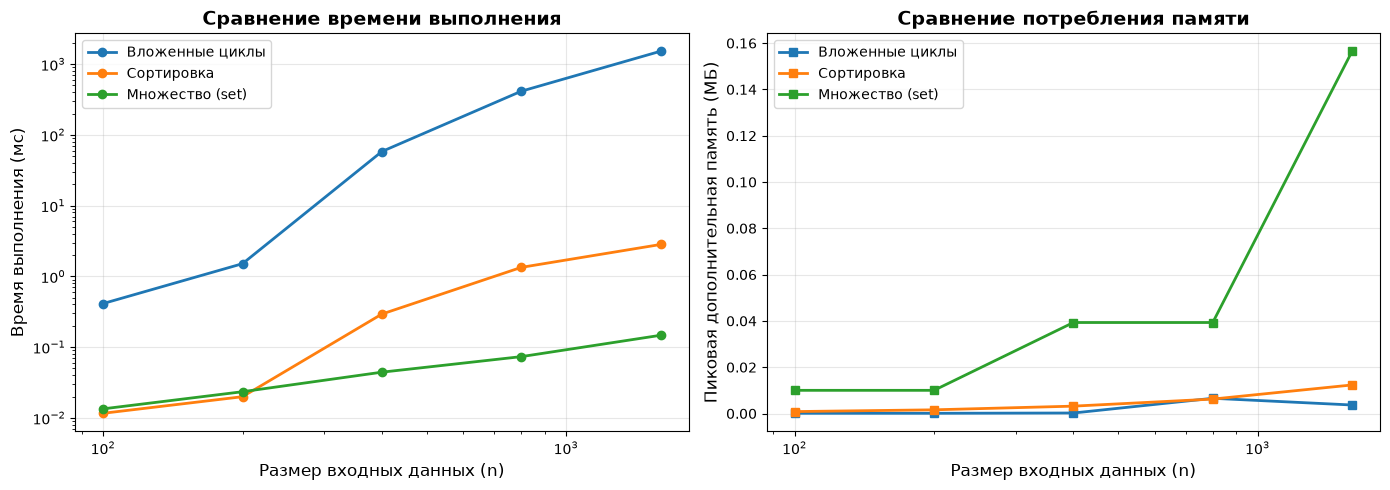


ИНТЕРПРЕТАЦИЯ:

1. Время: вложенные циклы растут катастрофически быстрее
   остальных. Сортировка и set близки, но set стабильно
   быстрее, потому что не тратит время на сортировку.

2. Память: set и сортировка требуют O(n) дополнительной
   памяти (сам set или копия списка). Вложенные циклы
   используют почти O(1) памяти — это их единственный
   плюс, но он не компенсирует медленность.

3. Вывод: set — лучший выбор в большинстве случаев.
   Сортировка оправдана, если данные уже частично
   отсортированы или нужна дополнительная обработка.



In [14]:
import time
import tracemalloc
import matplotlib.pyplot as plt

# ============================================================
# ПОЛНЫЙ ПРИМЕР: Поиск дубликатов тремя способами
# ============================================================

def has_duplicates_quadratic(arr):
    """Вложенные циклы — медленно"""
    n = len(arr)
    for i in range(n):
        for j in range(i + 1, n):
            if arr[i] == arr[j]:
                return True
    return False

def has_duplicates_sorting(arr):
    """Сортировка + проверка соседей"""
    sorted_arr = sorted(arr)
    for i in range(len(sorted_arr) - 1):
        if sorted_arr[i] == sorted_arr[i + 1]:
            return True
    return False

def has_duplicates_set(arr):
    """Через set — быстро"""
    seen = set()
    for x in arr:
        if x in seen:
            return True
        seen.add(x)
    return False

# --- Функция для замера времени и памяти ---
def benchmark(func, arr, repeat=3):
    """Возвращает (лучшее_время_сек, пиковая_память_МБ)."""
    times = []
    peaks = []
    for _ in range(repeat):
        tracemalloc.start()
        start = time.perf_counter()
        func(arr)
        end = time.perf_counter()
        current, peak = tracemalloc.get_traced_memory()
        tracemalloc.stop()
        times.append(end - start)
        peaks.append(peak / 1024 / 1024)
    return min(times), max(peaks)

# --- Генерируем данные разного размера ---
# Массивы без дубликатов, чтобы каждый алгоритм прошел весь путь
sizes = [100, 200, 400, 800, 1600]
algorithms = {
    "Вложенные циклы": has_duplicates_quadratic,
    "Сортировка":      has_duplicates_sorting,
    "Множество (set)": has_duplicates_set,
}

results_time = {name: [] for name in algorithms}
results_mem = {name: [] for name in algorithms}

print("Запуск бенчмарков...\n")
for n in sizes:
    arr = list(range(n))
    print(f"Размер n={n}:")
    for name, func in algorithms.items():
        t, m = benchmark(func, arr)
        results_time[name].append(t * 1000)  # мс
        results_mem[name].append(m)
        print(f"  {name:20s}  время={t*1000:8.3f} мс  память={m:6.2f} МБ")
    print()

# ============================================================
# ВИЗУАЛИЗАЦИЯ С MATPLOTLIB
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- График времени ---
ax = axes[0]
for name in algorithms:
    ax.plot(sizes, results_time[name], marker='o', label=name, linewidth=2)
ax.set_xlabel("Размер входных данных (n)", fontsize=12)
ax.set_ylabel("Время выполнения (мс)", fontsize=12)
ax.set_title("Сравнение времени выполнения", fontsize=14, fontweight='bold')
ax.set_xscale('log')
ax.set_yscale('log')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

# --- График памяти ---
ax = axes[1]
for name in algorithms:
    ax.plot(sizes, results_mem[name], marker='s', label=name, linewidth=2)
ax.set_xlabel("Размер входных данных (n)", fontsize=12)
ax.set_ylabel("Пиковая дополнительная память (МБ)", fontsize=12)
ax.set_title("Сравнение потребления памяти", fontsize=14, fontweight='bold')
ax.set_xscale('log')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================
# Интерпретация
# ============================================================
print("\n" + "="*60)
print("ИНТЕРПРЕТАЦИЯ:")
print("="*60)
print("""
1. Время: вложенные циклы растут катастрофически быстрее
   остальных. Сортировка и set близки, но set стабильно
   быстрее, потому что не тратит время на сортировку.

2. Память: set и сортировка требуют O(n) дополнительной
   памяти (сам set или копия списка). Вложенные циклы
   используют почти O(1) памяти — это их единственный
   плюс, но он не компенсирует медленность.

3. Вывод: set — лучший выбор в большинстве случаев.
   Сортировка оправдана, если данные уже частично
   отсортированы или нужна дополнительная обработка.
""")

Часть 3 (расширенная): Matplotlib для сравнения кода
3.1 Базовая структура: Figure и Axes
В matplotlib есть два подхода: старый plt.plot() (работает с «текущим» графиком) и объектный fig, ax = plt.subplots(). Для сравнения кода всегда используйте объектный — он даёт полный контроль над каждым элементом .

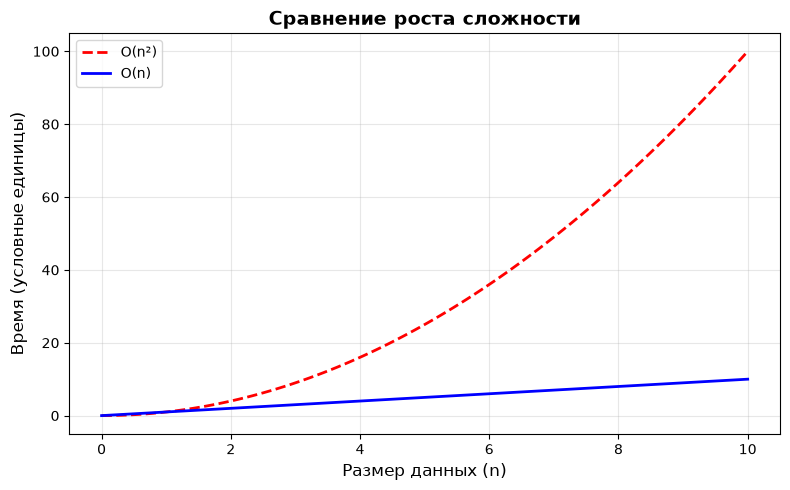

In [15]:
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# Пример 5: Figure и Axes — объектный подход
# ============================================================
# fig — всё окно (холст), ax — конкретная область с осями.

x = np.linspace(0, 10, 100)

# Создаём Figure с одной Axes
fig, ax = plt.subplots(figsize=(8, 5))

# Рисуем две линии с разными стилями
ax.plot(x, x**2, label="O(n²)", color="red", linestyle="--", linewidth=2)
ax.plot(x, x, label="O(n)", color="blue", linestyle="-", linewidth=2)

# Подписи осей и заголовок
ax.set_xlabel("Размер данных (n)", fontsize=12)
ax.set_ylabel("Время (условные единицы)", fontsize=12)
ax.set_title("Сравнение роста сложности", fontsize=14, fontweight="bold")

# Легенда — какая линия что означает
ax.legend(fontsize=10, loc="upper left")

# Сетка для удобства чтения
ax.grid(True, alpha=0.3)

plt.tight_layout()  # автоматически подгоняет отступы
plt.show()

3.2 Несколько графиков на одном рисунке: subplots
Для сравнения времени и памяти рядом нужны две Axes в одной Figure .

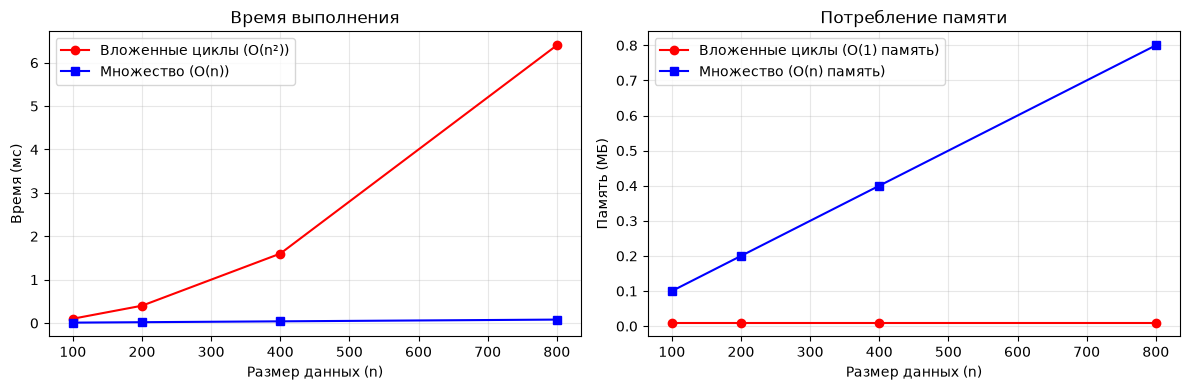

In [16]:
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# Пример 6: Два графика рядом (1 строка, 2 столбца)
# ============================================================

sizes = [100, 200, 400, 800]
time_quad = [0.1, 0.4, 1.6, 6.4]      # O(n²)
time_lin  = [0.01, 0.02, 0.04, 0.08]  # O(n)
mem_quad  = [0.01, 0.01, 0.01, 0.01]  # O(1) память
mem_lin   = [0.1, 0.2, 0.4, 0.8]      # O(n) память

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# --- Левый график: время ---
ax1.plot(sizes, time_quad, "ro-", label="Вложенные циклы (O(n²))")
ax1.plot(sizes, time_lin,  "bs-", label="Множество (O(n))")
ax1.set_xlabel("Размер данных (n)")
ax1.set_ylabel("Время (мс)")
ax1.set_title("Время выполнения")
ax1.legend()
ax1.grid(True, alpha=0.3)

# --- Правый график: память ---
ax2.plot(sizes, mem_quad, "ro-", label="Вложенные циклы (O(1) память)")
ax2.plot(sizes, mem_lin,  "bs-", label="Множество (O(n) память)")
ax2.set_xlabel("Размер данных (n)")
ax2.set_ylabel("Память (МБ)")
ax2.set_title("Потребление памяти")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

3.3 Логарифмические оси — когда разница в порядках
Если один алгоритм работает за миллисекунды, а другой за секунды, линейная шкала сделает быстрый график плоской линией у нуля. Логарифмическая шкала решает эту проблему.

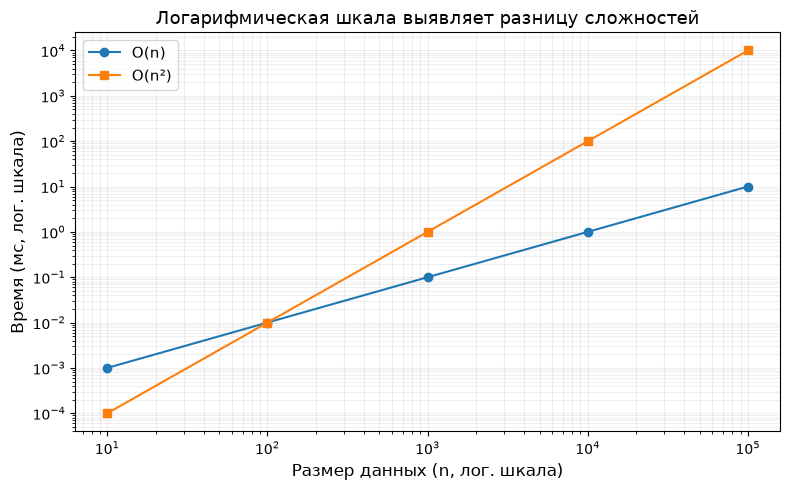

In [17]:
import matplotlib.pyplot as plt

# ============================================================
# Пример 7: Логарифмические оси
# ============================================================

sizes = [10, 100, 1000, 10000, 100000]
time_lin   = [0.001, 0.01, 0.1, 1.0, 10.0]
time_quad  = [0.0001, 0.01, 1.0, 100.0, 10000.0]

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(sizes, time_lin,  "o-", label="O(n)")
ax.plot(sizes, time_quad, "s-", label="O(n²)")

# Логарифм по обеим осям — видно, что O(n²) растёт гораздо круче
ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("Размер данных (n, лог. шкала)", fontsize=12)
ax.set_ylabel("Время (мс, лог. шкала)", fontsize=12)
ax.set_title("Логарифмическая шкала выявляет разницу сложностей", fontsize=13)
ax.legend(fontsize=11)
ax.grid(True, which="both", alpha=0.2)  # which="both" — сетка и для мелких делений

plt.tight_layout()
plt.show()

3.4 Две оси Y на одном графике: twinx
Иногда нужно показать время и память на одном графике, но у них разные единицы (мс и МБ). twinx() создаёт вторую ось Y справа, разделяющую ту же ось X .

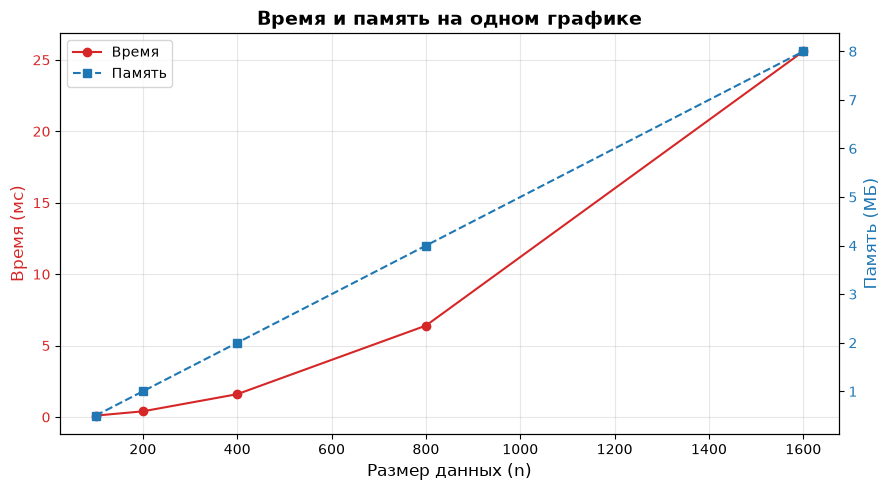

In [18]:
import matplotlib.pyplot as plt

# ============================================================
# Пример 8: twinx — время слева, память справа
# ============================================================

sizes = [100, 200, 400, 800, 1600]
time_ms = [0.1, 0.4, 1.6, 6.4, 25.6]
mem_mb  = [0.5, 1.0, 2.0, 4.0, 8.0]

fig, ax1 = plt.subplots(figsize=(9, 5))

# --- Левая ось: время ---
color_time = "tab:red"
ax1.set_xlabel("Размер данных (n)", fontsize=12)
ax1.set_ylabel("Время (мс)", color=color_time, fontsize=12)
line1 = ax1.plot(sizes, time_ms, "o-", color=color_time, label="Время")
ax1.tick_params(axis="y", labelcolor=color_time)

# --- Правая ось: память ---
ax2 = ax1.twinx()  # вторая ось Y, делит ту же X
color_mem = "tab:blue"
ax2.set_ylabel("Память (МБ)", color=color_mem, fontsize=12)
line2 = ax2.plot(sizes, mem_mb, "s--", color=color_mem, label="Память")
ax2.tick_params(axis="y", labelcolor=color_mem)

# Общая легенда для двух осей
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="upper left", fontsize=10)

ax1.set_title("Время и память на одном графике", fontsize=14, fontweight="bold")
ax1.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

3.5 Столбчатые диаграммы для категориальных сравнений
Когда нужно сравнить несколько алгоритмов на фиксированных размерах данных, столбцы читаются легче, чем линии.

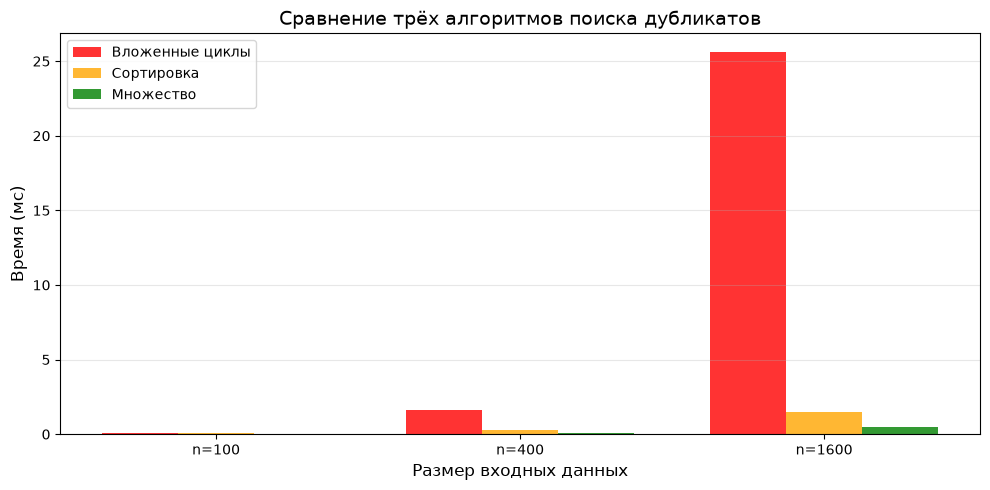

In [19]:
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# Пример 9: Группированные столбцы — время трёх алгоритмов
# ============================================================

algorithms = ["Вложенные циклы", "Сортировка", "Множество"]
sizes = ["n=100", "n=400", "n=1600"]

# Данные: строки — алгоритмы, столбцы — размеры
times = np.array([
    [0.1, 1.6, 25.6],   # вложенные циклы
    [0.05, 0.3, 1.5],   # сортировка
    [0.02, 0.1, 0.5],   # множество
])

x = np.arange(len(sizes))  # позиции групп по X
width = 0.25               # ширина одного столбца

fig, ax = plt.subplots(figsize=(10, 5))

# Три группы столбцов, сдвинутые друг относительно друга
ax.bar(x - width, times[0], width, label=algorithms[0], color="red", alpha=0.8)
ax.bar(x,          times[1], width, label=algorithms[1], color="orange", alpha=0.8)
ax.bar(x + width,  times[2], width, label=algorithms[2], color="green", alpha=0.8)

ax.set_xlabel("Размер входных данных", fontsize=12)
ax.set_ylabel("Время (мс)", fontsize=12)
ax.set_title("Сравнение трёх алгоритмов поиска дубликатов", fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(sizes)
ax.legend(fontsize=10)
ax.grid(True, axis="y", alpha=0.3)  # только горизонтальная сетка

plt.tight_layout()
plt.show()

3.8 Полный пример: все приёмы вместе
Соберём финальный скрипт, который сравнивает алгоритмы и рисует информативный дашборд.

Запуск...
  n=100: готово
  n=200: готово
  n=400: готово
  n=800: готово
  n=1600: готово


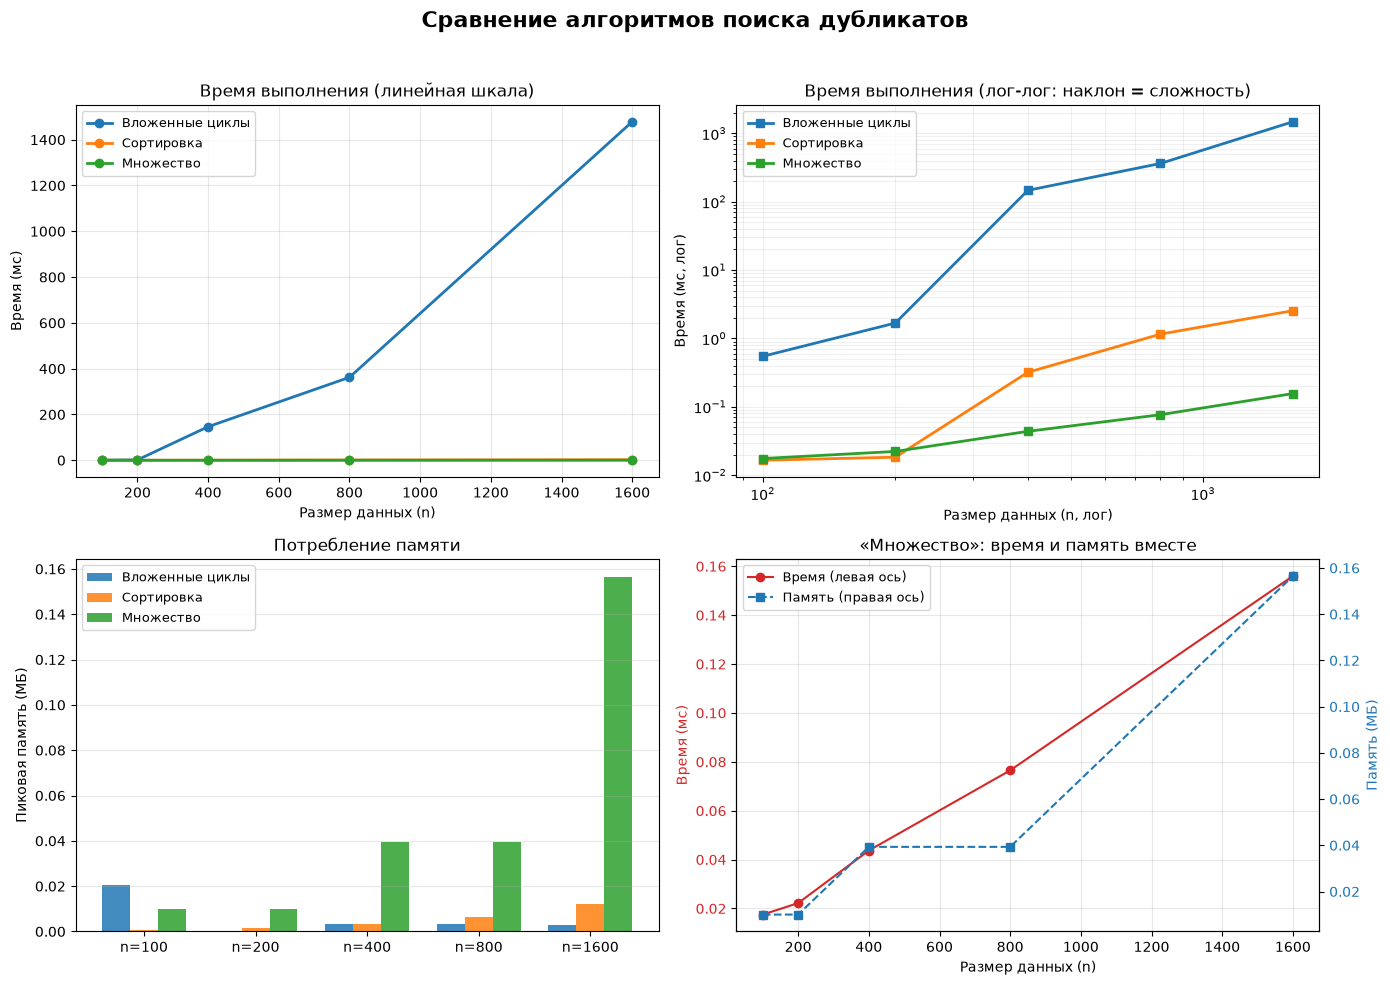


График сохранён: algorithm_comparison.png


In [ ]:
import time
import tracemalloc
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# ФИНАЛЬНЫЙ ПРИМЕР: Сравнение алгоритмов с полной визуализацией
# ============================================================

def has_duplicates_quadratic(arr):
    n = len(arr)
    for i in range(n):
        for j in range(i + 1, n):
            if arr[i] == arr[j]:
                return True
    return False

def has_duplicates_sorting(arr):
    sorted_arr = sorted(arr)
    for i in range(len(sorted_arr) - 1):
        if sorted_arr[i] == sorted_arr[i + 1]:
            return True
    return False

def has_duplicates_set(arr):
    seen = set()
    for x in arr:
        if x in seen:
            return True
        seen.add(x)
    return False

def benchmark(func, arr, repeat=3):
    times, peaks = [], []
    for _ in range(repeat):
        tracemalloc.start()
        start = time.perf_counter()
        func(arr)
        end = time.perf_counter()
        _, peak = tracemalloc.get_traced_memory()
        tracemalloc.stop()
        times.append(end - start)
        peaks.append(peak / 1024 / 1024)
    return min(times), max(peaks)

# --- Данные ---
sizes = [100, 200, 400, 800, 1600]
algorithms = {
    "Вложенные циклы": has_duplicates_quadratic,
    "Сортировка":      has_duplicates_sorting,
    "Множество":       has_duplicates_set,
}

res_time = {k: [] for k in algorithms}
res_mem  = {k: [] for k in algorithms}

print("Запуск...")
for n in sizes:
    arr = list(range(n))
    for name, func in algorithms.items():
        t, m = benchmark(func, arr)
        res_time[name].append(t * 1000)  # мс
        res_mem[name].append(m)          # МБ
    print(f"  n={n}: готово")

# ============================================================
# ВИЗУАЛИЗАЦИЯ: дашборд 2×2
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Сравнение алгоритмов поиска дубликатов", fontsize=16, fontweight="bold")

# --- (0,0) Линейный график времени ---
ax = axes[0, 0]
for name, data in res_time.items():
    ax.plot(sizes, data, marker="o", label=name, linewidth=2)
ax.set_xlabel("Размер данных (n)")
ax.set_ylabel("Время (мс)")
ax.set_title("Время выполнения (линейная шкала)")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

# --- (0,1) Лог-лог график времени ---
ax = axes[0, 1]
for name, data in res_time.items():
    ax.plot(sizes, data, marker="s", label=name, linewidth=2)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Размер данных (n, лог)")
ax.set_ylabel("Время (мс, лог)")
ax.set_title("Время выполнения (лог-лог: наклон = сложность)")
ax.legend(fontsize=9)
ax.grid(True, which="both", alpha=0.2)

# --- (1,0) Столбцы: память ---
ax = axes[1, 0]
x = np.arange(len(sizes))
width = 0.25
for i, (name, data) in enumerate(res_mem.items()):
    ax.bar(x + (i - 1) * width, data, width, label=name, alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels([f"n={n}" for n in sizes])
ax.set_ylabel("Пиковая память (МБ)")
ax.set_title("Потребление памяти")
ax.legend(fontsize=9)
ax.grid(True, axis="y", alpha=0.3)

# --- (1,1) twinx: время + память для «Множества» ---
ax1 = axes[1, 1]
name = "Множество"
ax1.plot(sizes, res_time[name], "o-", color="tab:red", label="Время (левая ось)")
ax1.set_xlabel("Размер данных (n)")
ax1.set_ylabel("Время (мс)", color="tab:red")
ax1.tick_params(axis="y", labelcolor="tab:red")

ax2 = ax1.twinx()
ax2.plot(sizes, res_mem[name], "s--", color="tab:blue", label="Память (правая ось)")
ax2.set_ylabel("Память (МБ)", color="tab:blue")
ax2.tick_params(axis="y", labelcolor="tab:blue")

ax1.set_title(f"«{name}»: время и память вместе")
ax1.grid(True, alpha=0.3)

# Объединённая легенда
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", fontsize=9)

plt.tight_layout(rect=[0, 0, 1, 0.96])  # место для suptitle
fig.savefig("algorithm_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
